# Where do Virginians stand on cutting foreign aid and public broadcasting? CES 2025 support by congressional district

**Author:** Calvin Pan
**Date created:** November 10, 2026
**Date last modified:** November 10, 2026

---

This notebook was created for Memo 3 (Considering the Public) in my Politics class (LPPP 6350).

It makes one figure. The top is a map of Virginia's 11 congressional districts. Each district is colored by its % support minus its % oppose for the 2025 bill that cut \$9.4 billion in previously allocated federal spending (CES item `CC25_340g`). That's \$8.3 billion in foreign aid and \$1.1 billion for NPR and PBS. Red means more support for the cut, blue means more opposition, and darker means a bigger margin. Each district shows its weighted % support. Below the map, a table compares VA-5, Virginia and the U.S. on three items: the cut, withdrawing from the World Health Organization (WHO), and sending aid to Ukraine.

### NOTE: Each district has only about 30 to 60 respondents, so district numbers are noisy.

The Cooperative Election Study (CES) 2025 Common Content is a national survey of 17,000 adults run by YouGov. District boundaries are the Census Bureau's 2024 cartographic boundary file for the 119th Congress, which is trimmed to the shoreline so the coastal districts look right. Both files are large, so `rawdata/` is in `.gitignore`.

Folder structure:

    python/ces25_va_aid_cut_map/
                        -- ces25_va_aid_cut_map.ipynb (this notebook)
                        -- rawdata (CES25_Common.dta + cb_2024_us_cd119_500k/; gitignored)
                        -- output (figure + table)

### 0. Install packages

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from shapely.geometry import box
from shapely.ops import polylabel
import os

### 1. Set directories

In [2]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPP 6350 Politics/stata/python/ces25_va_aid_cut_map/"
rawdata_dir = dir + "rawdata/"
output_dir = dir + "output/"

os.makedirs(rawdata_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

### 2. Load the CES and recode
The three items:

| Variable | Question | Coding |
|---|---|---|
| `CC25_340g` | Cut \$9.4 billion from previously allocated federal spending (\$8.3 billion in foreign aid, \$1.1 billion for NPR and PBS) | 1 Support, 2 Oppose |
| `CC25_342c` | Withdraw the U.S. from the WHO | 1 Support, 2 Oppose |
| `CC25_307_2`, `CC25_307_8` | What the U.S. should do about Ukraine: humanitarian aid; rebuilding aid (select all that apply) | 1 selected, 2 not selected |

8 (skipped) and 9 (not asked) become missing. "Aid to Ukraine" means the person picked humanitarian aid, rebuilding aid, or both. The labels in the data are cut off at 80 characters, so check the codebook for the full wording.

In [3]:
ces = pd.read_stata(rawdata_dir + "CES25_Common.dta", convert_categoricals=False,
                    columns=["inputstate", "cdid119", "commonweight", "CC25_340g", "CC25_342c", "CC25_307_2", "CC25_307_8"])

ces["aid_cut"] = ces["CC25_340g"].map({1: 1.0, 2: 0.0})
ces["withdraw_who"] = ces["CC25_342c"].map({1: 1.0, 2: 0.0})
ces["aid_ukraine"] = ((ces["CC25_307_2"] == 1) | (ces["CC25_307_8"] == 1)).astype(float).where(ces["CC25_307_2"].isin([1, 2]))

va = ces[ces["inputstate"] == 51]   # 51 = Virginia
print(len(ces), "respondents in the U.S.,", len(va), "in Virginia")

17000 respondents in the U.S., 420 in Virginia


### 3. Weighted support by district, Virginia and the U.S.
All numbers are weighted with `commonweight`, the CES weight for the common content. The margin is % support minus % oppose, which is what colors the map.

In [4]:
def weighted_pct(d, col):
    d = d.dropna(subset=[col])
    return {"pct": 100 * np.average(d[col], weights=d["commonweight"]), "n": len(d)}

# By district
districts = pd.DataFrame([{"cd": int(cd), **weighted_pct(d, "aid_cut")} for cd, d in va.groupby("cdid119")])
districts["margin"] = 2 * districts["pct"] - 100   # Support minus oppose
districts.round(1)

,cd,pct,n,margin
0,1,40.2,33,-19.6
1,2,65.8,42,31.6
2,3,46.9,39,-6.1
3,4,25.0,42,-50.1
4,5,57.4,42,14.8
5,6,68.5,28,36.9
6,7,50.6,35,1.1
7,8,23.5,33,-52.9
8,9,54.1,58,8.1
9,10,24.7,29,-50.5


In [5]:
# VA-5 vs. Virginia vs. the U.S.
geos = {"VA-5": va[va["cdid119"] == 5], "Virginia": va, "United States": ces}
items = {"aid_cut": "Support for cutting foreign aid & broadcasting funding",
         "withdraw_who": "Support withdrawing from the WHO",
         "aid_ukraine": "Send humanitarian or rebuilding aid to Ukraine"}

table = pd.DataFrame([{"item": label, "geography": g, **weighted_pct(d, col)}
                      for col, label in items.items() for g, d in geos.items()])
table.round(1).to_csv(output_dir + "table1_va5_va_us.csv", index=False)
table.round(1)

,item,geography,pct,n
0,Support for cutting foreign aid & broadcasting...,VA-5,57.4,42
1,Support for cutting foreign aid & broadcasting...,Virginia,45.0,418
2,Support for cutting foreign aid & broadcasting...,United States,47.5,16821
3,Support withdrawing from the WHO,VA-5,35.9,42
4,Support withdrawing from the WHO,Virginia,32.2,417
5,Support withdrawing from the WHO,United States,33.3,16891
6,Send humanitarian or rebuilding aid to Ukraine,VA-5,58.7,43
7,Send humanitarian or rebuilding aid to Ukraine,Virginia,60.6,420
8,Send humanitarian or rebuilding aid to Ukraine,United States,55.6,17000


### 4. Figure 1: map and table
- **Colors:** the scale is centered at 0, so white means an even split. It runs to the same distance on each side, so a given shade of red and of blue mean the same size margin.
- **Borders:** every district has the same white border.
- **Insets:** VA-8 and VA-11 (Northern Virginia) and VA-2 and VA-3 (Hampton Roads) are too small to label on the full map, so they get zoomed insets.
- **Labels:** each sits at the point inside the district that is farthest from its edges (`polylabel`), so labels stay inside narrow districts.
- **Width:** the map axis uses `adjustable="datalim"` so it fills the full width of the figure. That way the table below it is the same width.

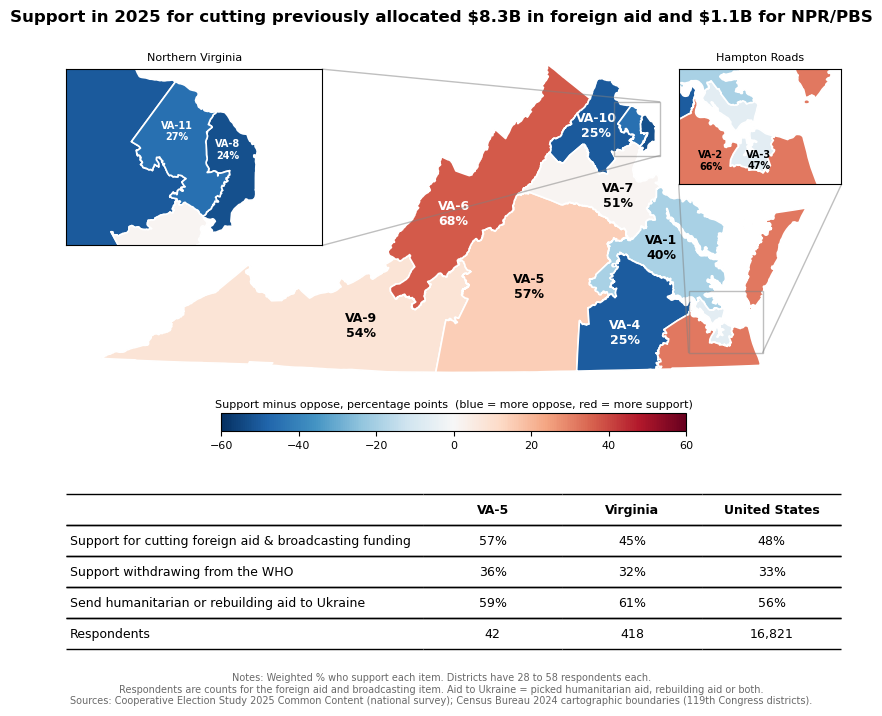

In [6]:
shp = gpd.read_file(rawdata_dir + "cb_2024_us_cd119_500k/cb_2024_us_cd119_500k.shp")
va_map = shp[shp["STATEFP"] == "51"].copy()
va_map["cd"] = va_map["CD119FP"].astype(int)
va_map = va_map.merge(districts, on="cd").to_crs(epsg=3968)   # NAD83 / Virginia Lambert

lim = np.ceil(districts["margin"].abs().max() / 10) * 10      # Symmetric color scale, rounded up to the next 10 points
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
cmap = plt.get_cmap("RdBu_r")
insets = {"Northern Virginia": [8, 11], "Hampton Roads": [2, 3]}   # Too small to label on the full map; labeled in insets


def label_point(geom, window=None):
    if window is not None:                                     # In an inset, label the part of the district inside the zoom
        geom = geom.intersection(box(*window))
    if geom.geom_type == "MultiPolygon":                       # VA-2 includes the Eastern Shore; label the biggest piece
        geom = max(geom.geoms, key=lambda g: g.area)
    return polylabel(geom, tolerance=100)                     # Point farthest from the edges (100 m precision)


def draw(ax, label_cds, fontsize, window=None):
    va_map.plot(column="margin", cmap=cmap, norm=norm, edgecolor="white", linewidth=1.2, ax=ax)
    for _, r in va_map[va_map["cd"].isin(label_cds)].iterrows():
        p = label_point(r.geometry, window)
        color = "white" if abs(r["margin"]) > 0.55 * lim else "black"
        ax.annotate(f"VA-{r['cd']}\n{r['pct']:.0f}%", (p.x, p.y), ha="center", va="center",
                    fontsize=fontsize, fontweight="bold", color=color)


fig = plt.figure(figsize=(10, 7.8))
gs = fig.add_gridspec(3, 1, height_ratios=[3.5, 0.9, 1.6], hspace=0.05)
ax, ax_cb, ax_tab = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])

# Map
inset_cds = sum(insets.values(), [])
draw(ax, [cd for cd in va_map["cd"] if cd not in inset_cds], fontsize=9)
ax.set_aspect("equal", adjustable="datalim")
ax.axis("off")

# Insets: Northern Virginia top left, Hampton Roads top right (both corners are empty)
positions = {"Northern Virginia": [0.0, 0.42, 0.33, 0.52], "Hampton Roads": [0.79, 0.6, 0.21, 0.34]}
for name, cds in insets.items():
    if name == "Hampton Roads":                                # Zoom on the mainland part; the Eastern Shore stays on the full map
        xmin, ymin, xmax, ymax = va_map[va_map["cd"] == 3].total_bounds
        xmax = xmax + 0.6 * (xmax - xmin)
    else:
        xmin, ymin, xmax, ymax = va_map[va_map["cd"].isin(cds)].total_bounds
    pad = 0.1 * (xmax - xmin)
    window = (xmin - pad, ymin - pad, xmax + pad, ymax + pad)
    inset = ax.inset_axes(positions[name])
    draw(inset, cds, fontsize=7, window=window)
    inset.set_xlim(window[0], window[2])
    inset.set_ylim(window[1], window[3])
    inset.set_aspect("equal", adjustable="datalim")
    inset.set_xticks([])
    inset.set_yticks([])
    inset.set_title(name, fontsize=8)
    ax.indicate_inset_zoom(inset, edgecolor="gray")

# Color bar: sits in the top part of its row so the tick labels clear the table
ax_cb.axis("off")
cax = ax_cb.inset_axes([0.2, 0.62, 0.6, 0.2])
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
cb.set_label("Support minus oppose, percentage points  (blue = more oppose, red = more support)", fontsize=8)
cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=8)

# Table
ax_tab.axis("off")
cell_text = [[label] + [f"{r['pct']:.0f}%" for _, r in table[table["item"] == label].iterrows()] for label in items.values()]
cell_text.append(["Respondents"] + [f"{n:,}" for n in table[table["item"] == items["aid_cut"]]["n"]])
tab = ax_tab.table(cellText=cell_text, colLabels=[""] + list(geos), colWidths=[0.46, 0.18, 0.18, 0.18],
                   cellLoc="center", bbox=[0, 0, 1, 1])
tab.auto_set_font_size(False)
tab.set_fontsize(9)
for (row, col), c in tab.get_celld().items():
    c.visible_edges = "horizontal"
    if row == 0:
        c.set_text_props(fontweight="bold")
    if col == 0:
        c.set_text_props(ha="left")
        c.PAD = 0.01

fig.suptitle("Support in 2025 for cutting previously allocated \\$8.3B in foreign aid and \\$1.1B for NPR/PBS",
             fontweight="bold", fontsize=12, y=0.93)
fig.text(0.5, 0.08,
         f"Notes: Weighted % who support each item. Districts have {districts['n'].min()} to {districts['n'].max()} respondents each.\n"
         "Respondents are counts for the foreign aid and broadcasting item. Aid to Ukraine = picked humanitarian aid, rebuilding aid or both.\n"
         "Sources: Cooperative Election Study 2025 Common Content (national survey); "
         "Census Bureau 2024 cartographic boundaries (119th Congress districts).",
         ha="center", va="top", fontsize=7, color="dimgray")

plt.savefig(output_dir + "fig1_va_aid_cut_map.png", dpi=200, bbox_inches="tight")
plt.show()